# 06 · Synthetic Dominion
We build a "synthetic" Dominion as a weighted mix of PJM zones with few data centers, chosen so that it follows the real Dominion price as closely as possible **before** the boom (2019–2022). After 2022, the gap between real and synthetic Dominion is our estimate of the local data center effect (Section 2.2.3 of the thesis).

Donors exclude the other exposed zones (AEP, ComEd, PSEG) and Dominion's neighbours (BGE, Pepco, APS), which share its grid constraints and would carry part of the same effect.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from utils import RAW, CLEAN, save_fig

zone = pd.read_parquet(CLEAN / "panel_zone_month.parquet")
Y = zone.pivot_table(index="month", columns="zone", values="wholesale_real")
DONORS = [z for z in Y.columns if z not in ["DOM", "AEP", "COMED", "PSEG", "BGE", "PEPCO", "APS"]]
PRE = Y.index <= "2022-12-01"
LATEST = Y.index >= "2025-08-01"

## 1. The weights
Weights are non-negative and sum to 1; they minimise the squared gap before 2023. Result: Met-Ed 48%, Dayton 35%, Duke Ohio/Kentucky 18%; gap in the latest 12 months 34.1 $/MWh.

In [2]:
def synth_weights(target, donors):
    X, y = Y.loc[PRE, donors].values, Y.loc[PRE, target].values
    n = len(donors)
    res = minimize(lambda w: ((y - X @ w) ** 2).mean(), np.full(n, 1 / n), bounds=[(0, 1)] * n,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
    return pd.Series(res.x, index=donors)

w = synth_weights("DOM", DONORS)
synthetic = Y[DONORS] @ w
gap = Y["DOM"] - synthetic
print(w[w > 0.01].round(2).sort_values(ascending=False).to_string())
print(f"Pre-2023 fit (RMSE): {np.sqrt((gap[PRE] ** 2).mean()):.1f} $/MWh")
print(f"Average gap, latest 12 months: {gap[LATEST].mean():.1f} $/MWh")

METED    0.48
DAY      0.35
DEOK     0.18
Pre-2023 fit (RMSE): 6.7 $/MWh
Average gap, latest 12 months: 34.1 $/MWh


## 2. Real vs synthetic Dominion (Figure 2.4)
The bottom panel shows the gap as a 3-month average; the dotted lines mark the public launch of ChatGPT and the Stargate announcement.

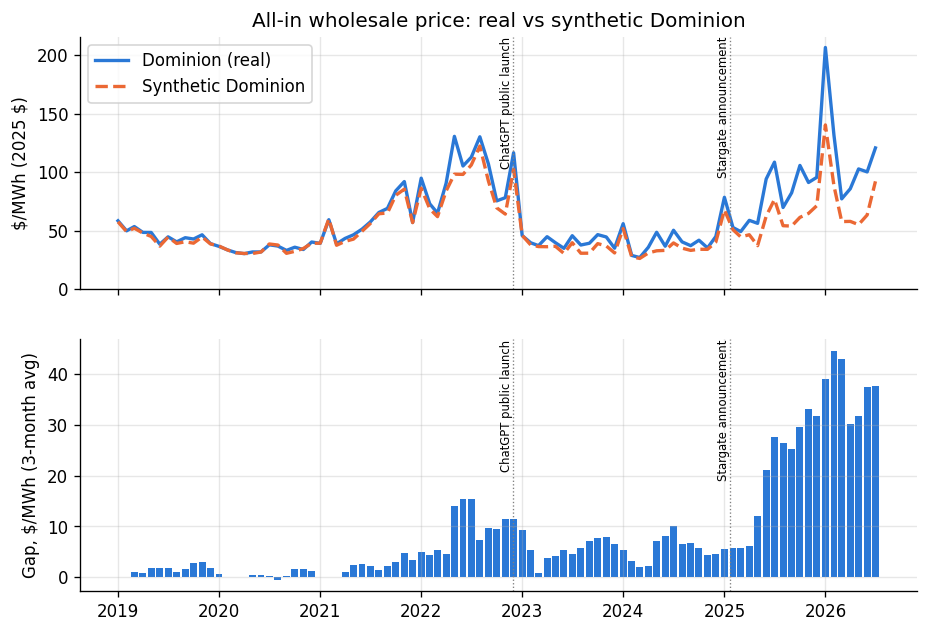

In [3]:
events = pd.read_csv(RAW / "manual/events.csv", parse_dates=["date"])
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(Y.index, Y["DOM"], color="#2a78d6", lw=2, label="Dominion (real)")
axes[0].plot(Y.index, synthetic, color="#eb6834", lw=2, ls="--", label="Synthetic Dominion")
axes[0].set(ylabel="$/MWh (2025 $)", title="All-in wholesale price: real vs synthetic Dominion"); axes[0].legend()
axes[0].set_ylim(bottom=0)
axes[1].bar(gap.index, gap.rolling(3).mean(), width=25, color="#2a78d6")
axes[1].set(ylabel="Gap, $/MWh (3-month avg)")
for ax in axes:
    for _, e in events[events.type == "ai"].iterrows():
        ax.axvline(e.date, color="grey", lw=0.8, ls=":")
        ax.annotate(e.event.split(" (")[0], (e.date, ax.get_ylim()[1]), fontsize=7, rotation=90, va="top", ha="right")
save_fig("06_synthetic_dom")

## 3. Placebo test
We pretend each donor zone is the treated one and build its own synthetic version. If Dominion has the largest post/pre error ratio, the gap is unlikely to be chance. p-value = share of zones with a ratio at least as large as Dominion's (1 of 14 = 0.07).

In [4]:
def ratio(target, donors):
    g = Y[target] - Y[donors] @ synth_weights(target, donors)
    return np.sqrt((g[~PRE] ** 2).mean()) / np.sqrt((g[PRE] ** 2).mean())

ratios = pd.Series({z: ratio(z, [d for d in DONORS if d != z]) for z in DONORS})
ratios["DOM"] = ratio("DOM", DONORS)
p_value = (ratios >= ratios["DOM"]).mean()
print(ratios.sort_values(ascending=False).round(2).head(6).to_string())
print(f"Placebo p-value: {p_value:.2f}")

DOM        3.19
PENELEC    3.07
PPL        1.84
EKPC       1.80
DPL        1.40
DEOK       1.28
Placebo p-value: 0.07


## Save
`synthetic_summary.csv` is read by notebook 08.

In [5]:
out = pd.DataFrame({"real": Y["DOM"], "synthetic": synthetic, "gap": gap})
out.to_csv(CLEAN / "synthetic_dom.csv")
pd.DataFrame([{"gap_latest12m": gap[LATEST].mean(), "gap_2025": gap[gap.index.year == 2025].mean(),
               "pre_rmse": np.sqrt((gap[PRE] ** 2).mean()), "placebo_p": p_value}]).to_csv(CLEAN / "synthetic_summary.csv", index=False)